In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.14.0+cpu
Device: cpu


In [2]:

manifest = "../data/realwaste_data.csv"
dataset_root = "../data/RealWaste"

print(manifest)
print(dataset_root)

../data/realwaste_data.csv
../data/RealWaste


In [4]:
print("Manifest exists:", os.path.exists(manifest))
print("Dataset folder exists:", os.path.isdir(dataset_root))

if os.path.isdir(dataset_root):
    print("Classes:", sorted(os.listdir(dataset_root)))

Manifest exists: True
Dataset folder exists: True
Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']


In [5]:

from torchvision.datasets import ImageFolder
from torch.utils.data import Subset
from sklearn.model_selection import train_test_split
from collections import Counter

# Load image paths and their class labels
base_dataset = ImageFolder(dataset_root)

class_names = base_dataset.classes
targets = np.array(base_dataset.targets)
indices = np.arange(len(targets))


train_indices, temp_indices = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=targets
)

val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=42,
    stratify=targets[temp_indices]
)

print("Total images:", len(base_dataset))
print("Training images:", len(train_indices))
print("Validation images:", len(val_indices))
print("Test images:", len(test_indices))
print("Classes:", class_names)


Total images: 4752
Training images: 3326
Validation images: 713
Test images: 713
Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']


In [6]:

# Image transformations
train_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Create datasets with the appropriate transformations
train_dataset_full = ImageFolder(dataset_root, transform=train_tf)
eval_dataset_full = ImageFolder(dataset_root, transform=eval_tf)

train_dataset = Subset(train_dataset_full, train_indices)
val_dataset = Subset(eval_dataset_full, val_indices)
test_dataset = Subset(eval_dataset_full, test_indices)

# Create data loaders
batch_size = 64

train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=batch_size, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Check one batch
images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)


Training batches: 52
Validation batches: 12
Test batches: 12
Image batch shape: torch.Size([64, 3, 64, 64])
Label batch shape: torch.Size([64])


In [7]:

class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        # Depthwise convolution: spatial feature extraction
        self.depthwise = nn.Sequential(
            nn.Conv2d(
                in_channels,
                in_channels,
                kernel_size=3,
                stride=1,
                padding=1,
                groups=in_channels,
                bias=False
            ),
            nn.BatchNorm2d(in_channels),
            nn.ReLU(inplace=True)
        )

        # Pointwise convolution: combine information across channels
        self.pointwise = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1,
                stride=1,
                padding=0,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        x = self.depthwise(x)
        x = self.pointwise(x)
        return x


class WasteImageNNLight(nn.Module):
    def __init__(self, num_classes=9):
        super().__init__()

        self.features = nn.Sequential(
            # Input: 3 x 64 x 64
            DepthwiseSeparableConv(3, 32),
            nn.MaxPool2d(2),  # 32 x 32 x 32

            DepthwiseSeparableConv(32, 64),
            nn.MaxPool2d(2),  # 64 x 16 x 16

            DepthwiseSeparableConv(64, 128),
            nn.MaxPool2d(2)   # 128 x 8 x 8
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),  # 128 x 1 x 1
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


# Create Model B
model_light = WasteImageNNLight().to(device)

total_params = sum(
    p.numel() for p in model_light.parameters() if p.requires_grad
)

print(model_light)
print(f"\nTrainable parameters: {total_params:,}")


WasteImageNNLight(
  (features): Sequential(
    (0): DepthwiseSeparableConv(
      (depthwise): Sequential(
        (0): Conv2d(3, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=3, bias=False)
        (1): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (pointwise): Sequential(
        (0): Conv2d(3, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
    )
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): DepthwiseSeparableConv(
      (depthwise): Sequential(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )


In [10]:

def train(model, train_loader, val_loader, num_ephohs, lr=1e-3):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()

    # Adam optimizer
    optimizer = optim.Adam(model.parameters(), lr=lr)

    train_losses = []
    validation_losses = []

    print(f"Training for {num_ephohs} epochs...")

    for epoch in range(num_ephohs):
        # Training phase
        model.train()
        running_train_loss = 0.0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_train_loss += loss.item()

        avg_train_loss = running_train_loss / len(train_loader)
        train_losses.append(avg_train_loss)

        # Validation phase
        model.eval()
        running_val_loss = 0.0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                running_val_loss += loss.item()

        avg_val_loss = running_val_loss / len(val_loader)
        validation_losses.append(avg_val_loss)

        print(
            f"Epoch [{epoch + 1}/{num_ephohs}] | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Validation Loss: {avg_val_loss:.4f}"
        )

    print("Training completed!")
    return train_losses, validation_losses


def plot_training_loss(train_losses, validation_losses):
    plt.figure(figsize=(8, 5))
    plt.plot(train_losses, label="Training Loss")
    plt.plot(validation_losses, label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Model B Training and Validation Loss")
    plt.legend()
    plt.grid(True)
    plt.show()


Training for 20 epochs...
Epoch [1/20] | Train Loss: 2.0007 | Validation Loss: 1.8015
Epoch [2/20] | Train Loss: 1.7028 | Validation Loss: 1.5469
Epoch [3/20] | Train Loss: 1.5102 | Validation Loss: 1.4479
Epoch [4/20] | Train Loss: 1.4426 | Validation Loss: 1.3683
Epoch [5/20] | Train Loss: 1.3696 | Validation Loss: 1.3083
Epoch [6/20] | Train Loss: 1.3303 | Validation Loss: 1.3104
Epoch [7/20] | Train Loss: 1.2937 | Validation Loss: 1.2763
Epoch [8/20] | Train Loss: 1.2654 | Validation Loss: 1.2271
Epoch [9/20] | Train Loss: 1.2368 | Validation Loss: 1.2628
Epoch [10/20] | Train Loss: 1.2173 | Validation Loss: 1.1974
Epoch [11/20] | Train Loss: 1.1852 | Validation Loss: 1.2343
Epoch [12/20] | Train Loss: 1.1655 | Validation Loss: 1.5336
Epoch [13/20] | Train Loss: 1.1682 | Validation Loss: 1.1538
Epoch [14/20] | Train Loss: 1.1196 | Validation Loss: 1.1357
Epoch [15/20] | Train Loss: 1.1215 | Validation Loss: 1.0666
Epoch [16/20] | Train Loss: 1.1248 | Validation Loss: 1.2306
Epoch [

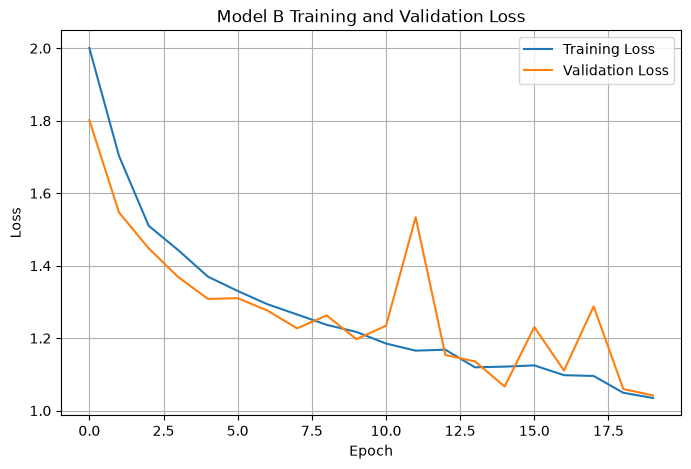

In [11]:

train_loss, validation_loss = train(
    model=model_light,
    train_loader=train_loader,
    val_loader=val_loader,
    num_ephohs=20,
    lr=1e-3
)

plot_training_loss(
    train_losses=train_loss,
    validation_losses=validation_loss
)


In [12]:

import os
import torch
import numpy as np

os.makedirs("../models", exist_ok=True)

# Save trained model weights
torch.save(
    model_light.state_dict(),
    "../models/model_light_epoch20.pth"
)

# Save the loss history
np.savez(
    "../models/model_light_epoch20_losses.npz",
    train_loss=np.array(train_loss),
    validation_loss=np.array(validation_loss)
)

print("Model B saved successfully!")
print("Trainable parameters:",
      sum(p.numel() for p in model_light.parameters() if p.requires_grad))


Model B saved successfully!
Trainable parameters: 47210


In [13]:

model_light.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model_light(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

# Overall metrics
test_accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(
    all_labels, all_predictions,
    average="weighted", zero_division=0
)
recall = recall_score(
    all_labels, all_predictions,
    average="weighted", zero_division=0
)
f1 = f1_score(
    all_labels, all_predictions,
    average="weighted", zero_division=0
)

print("MODEL B — AFTER 20 EPOCHS")
print(f"Test Accuracy:      {test_accuracy * 100:.2f}%")
print(f"Weighted Precision: {precision:.4f}")
print(f"Weighted Recall:    {recall:.4f}")
print(f"Weighted F1-score:  {f1:.4f}")

# Confusion matrix
cm = confusion_matrix(
    all_labels, all_predictions,
    labels=list(range(len(class_names)))
)

print("\nConfusion Matrix:")
print(cm)

# Per-class metrics
print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))


MODEL B — AFTER 20 EPOCHS
Test Accuracy:      61.85%
Weighted Precision: 0.6192
Weighted Recall:    0.6185
Weighted F1-score:  0.5909

Confusion Matrix:
[[49  1  2  2  0  7  8  0  0]
 [ 0 50  0  1  0  0  6  0  5]
 [ 0  1 40 14  1  0  7  0  0]
 [ 0  1  4 89  2  2 20  0  0]
 [ 0  8  9 22  6  5 17  2  6]
 [ 3  1  5  8  0 50  8  0  0]
 [ 0  7  7 27  3  2 92  0  0]
 [ 0  0  0  9  7 10  8  8  6]
 [ 0  5  1  1  1  0  0  0 57]]

Classification Report:
                     precision    recall  f1-score   support

          Cardboard     0.9423    0.7101    0.8099        69
      Food Organics     0.6757    0.8065    0.7353        62
              Glass     0.5882    0.6349    0.6107        63
              Metal     0.5145    0.7542    0.6117       118
Miscellaneous Trash     0.3000    0.0800    0.1263        75
              Paper     0.6579    0.6667    0.6623        75
            Plastic     0.5542    0.6667    0.6053       138
      Textile Trash     0.8000    0.1667    0.2759        48
  

In [14]:
# Save the baseline evaluation metrics
model_b_results_20 = {
    "test_accuracy": test_accuracy,
    "weighted_precision": precision,
    "weighted_recall": recall,
    "weighted_f1": f1,
    "confusion_matrix": cm
}

np.savez(
    "../models/model_light_epoch20_metrics.npz",
    test_accuracy=test_accuracy,
    weighted_precision=precision,
    weighted_recall=recall,
    weighted_f1=f1,
    confusion_matrix=cm
)

print("20-epoch baseline metrics saved.")

20-epoch baseline metrics saved.


Training for 20 epochs...
Epoch [1/20] | Train Loss: 1.0397 | Validation Loss: 0.9968
Epoch [2/20] | Train Loss: 1.0251 | Validation Loss: 1.0264
Epoch [3/20] | Train Loss: 1.0238 | Validation Loss: 1.0396
Epoch [4/20] | Train Loss: 0.9981 | Validation Loss: 1.1131
Epoch [5/20] | Train Loss: 0.9941 | Validation Loss: 0.9808
Epoch [6/20] | Train Loss: 1.0020 | Validation Loss: 0.9922
Epoch [7/20] | Train Loss: 0.9845 | Validation Loss: 0.9612
Epoch [8/20] | Train Loss: 0.9851 | Validation Loss: 0.9619
Epoch [9/20] | Train Loss: 0.9606 | Validation Loss: 1.1557
Epoch [10/20] | Train Loss: 0.9547 | Validation Loss: 0.9307
Epoch [11/20] | Train Loss: 0.9535 | Validation Loss: 1.1091
Epoch [12/20] | Train Loss: 0.9304 | Validation Loss: 0.9825
Epoch [13/20] | Train Loss: 0.9309 | Validation Loss: 1.1418
Epoch [14/20] | Train Loss: 0.9331 | Validation Loss: 1.1851
Epoch [15/20] | Train Loss: 0.9535 | Validation Loss: 0.9763
Epoch [16/20] | Train Loss: 0.9358 | Validation Loss: 1.1615
Epoch [

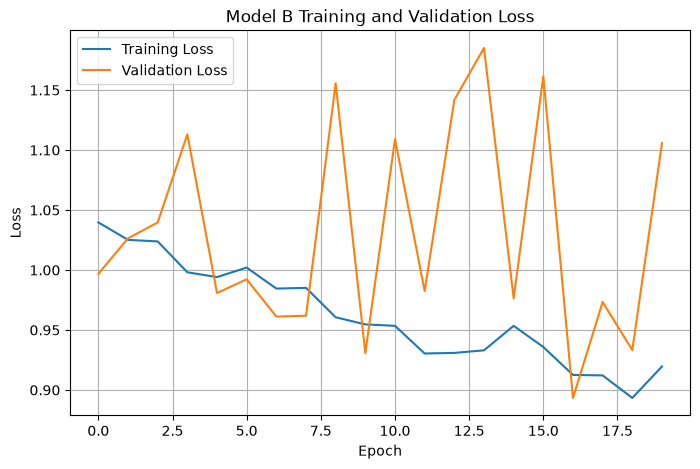

In [15]:
train_loss_more, validation_loss_more = train(
    model=model_light,
    train_loader=train_loader,
    val_loader=val_loader,
    num_ephohs=20,
    lr=1e-3
)

plot_training_loss(
    train_losses=train_loss_more,
    validation_losses=validation_loss_more
)

In [16]:
torch.save(
    model_light.state_dict(),
    "../models/model_light_epoch40.pth"
)

np.savez(
    "../models/model_light_epoch40_losses.npz",
    train_loss=np.concatenate([train_loss, train_loss_more]),
    validation_loss=np.concatenate([
        validation_loss,
        validation_loss_more
    ])
)

print("40-epoch model saved successfully.")

40-epoch model saved successfully.


In [17]:
model_light.eval()

all_predictions_40 = []
all_labels_40 = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model_light(images)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions_40.extend(predictions.cpu().numpy())
        all_labels_40.extend(labels.numpy())

# Calculate evaluation metrics
test_accuracy_40 = accuracy_score(
    all_labels_40, all_predictions_40
)

precision_40 = precision_score(
    all_labels_40, all_predictions_40,
    average="weighted", zero_division=0
)

recall_40 = recall_score(
    all_labels_40, all_predictions_40,
    average="weighted", zero_division=0
)

f1_40 = f1_score(
    all_labels_40, all_predictions_40,
    average="weighted", zero_division=0
)

print("MODEL B — AFTER 40 EPOCHS")
print(f"Test Accuracy:      {test_accuracy_40 * 100:.2f}%")
print(f"Weighted Precision: {precision_40:.4f}")
print(f"Weighted Recall:    {recall_40:.4f}")
print(f"Weighted F1-score:  {f1_40:.4f}")

cm_40 = confusion_matrix(
    all_labels_40,
    all_predictions_40,
    labels=list(range(len(class_names)))
)

print("\nConfusion Matrix:")
print(cm_40)

print("\nClassification Report:")
print(classification_report(
    all_labels_40,
    all_predictions_40,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))

MODEL B — AFTER 40 EPOCHS
Test Accuracy:      60.31%
Weighted Precision: 0.6323
Weighted Recall:    0.6031
Weighted F1-score:  0.5979

Confusion Matrix:
[[ 52   1   3   2   0   5   6   0   0]
 [  1  48   1   1   1   0   9   0   1]
 [  0   0  33  11   0   1  13   5   0]
 [  0   1   1  62   5  14  26   9   0]
 [  0   6   2   3  16   9  26  13   0]
 [  6   0   3   0   1  58   6   1   0]
 [  2   1   4  17   1   1 100  12   0]
 [  0   0   0   1   2  10   7  27   1]
 [  0   6   3   3   6   1   5   7  34]]

Classification Report:
                     precision    recall  f1-score   support

          Cardboard     0.8525    0.7536    0.8000        69
      Food Organics     0.7619    0.7742    0.7680        62
              Glass     0.6600    0.5238    0.5841        63
              Metal     0.6200    0.5254    0.5688       118
Miscellaneous Trash     0.5000    0.2133    0.2991        75
              Paper     0.5859    0.7733    0.6667        75
            Plastic     0.5051    0.7246   